# 3. Coverage and transit

**Questions.** How many of the nine everyday categories are within 15 minutes (measure M4, the headline), and what share of residents is within 500 m of a bus or jeepney and 1 km of rail, the UN's test of convenient public transport (RQ4, M5)?

**Method.**

- **M4** counts the categories with at least one service within 15 minutes (1,050 m), unweighted.
- **M5** follows SDG indicator 11.2.1 by street distance: 500 m to a bus stop, bus terminal or jeepney or bus route (jeepneys stop anywhere along their route), and 1 km to an LRT or MRT station. Only 95 jeepney routes are mapped in the study area (`docs/data-quality.md`), so jeepney access is a floor.

In [1]:
import sys
from pathlib import Path

# The notebooks import their logic from src/: the shared helpers and the analysis functions.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "shared").is_dir())
for folder in ("src/shared", "src/03_analyse"):
    sys.path.insert(0, str(ROOT / folder))

import charts
import measures
import pandas as pd
from common import TABLES
from IPython.display import Image

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
AREAS = measures.STUDY + ["Metro Manila"]
m = pd.read_csv(TABLES / "measures.csv")

In [2]:
m4 = m[(m.measure == "M4") & m.area.isin(AREAS)].pivot_table(index="stat", columns="area", values="value", sort=False)[
    AREAS
]
m4.round(2)

area,Barangay 136,Loyola Heights,Oranbo,Metro Manila
stat,,,,
mean_categories_within_15min,8.74,6.51,7.72,6.98
median_categories_within_15min,9.00,7.00,8.00,7.00
share_with_0,0.00,0.00,0.00,0.00
share_with_1,0.00,0.00,0.00,0.01
share_with_2,0.00,0.01,0.00,0.02
share_with_3,0.00,0.03,0.00,0.03
share_with_4,0.00,0.03,0.00,0.05
share_with_5,0.00,0.13,0.04,0.09
share_with_6,0.00,0.29,0.02,0.13


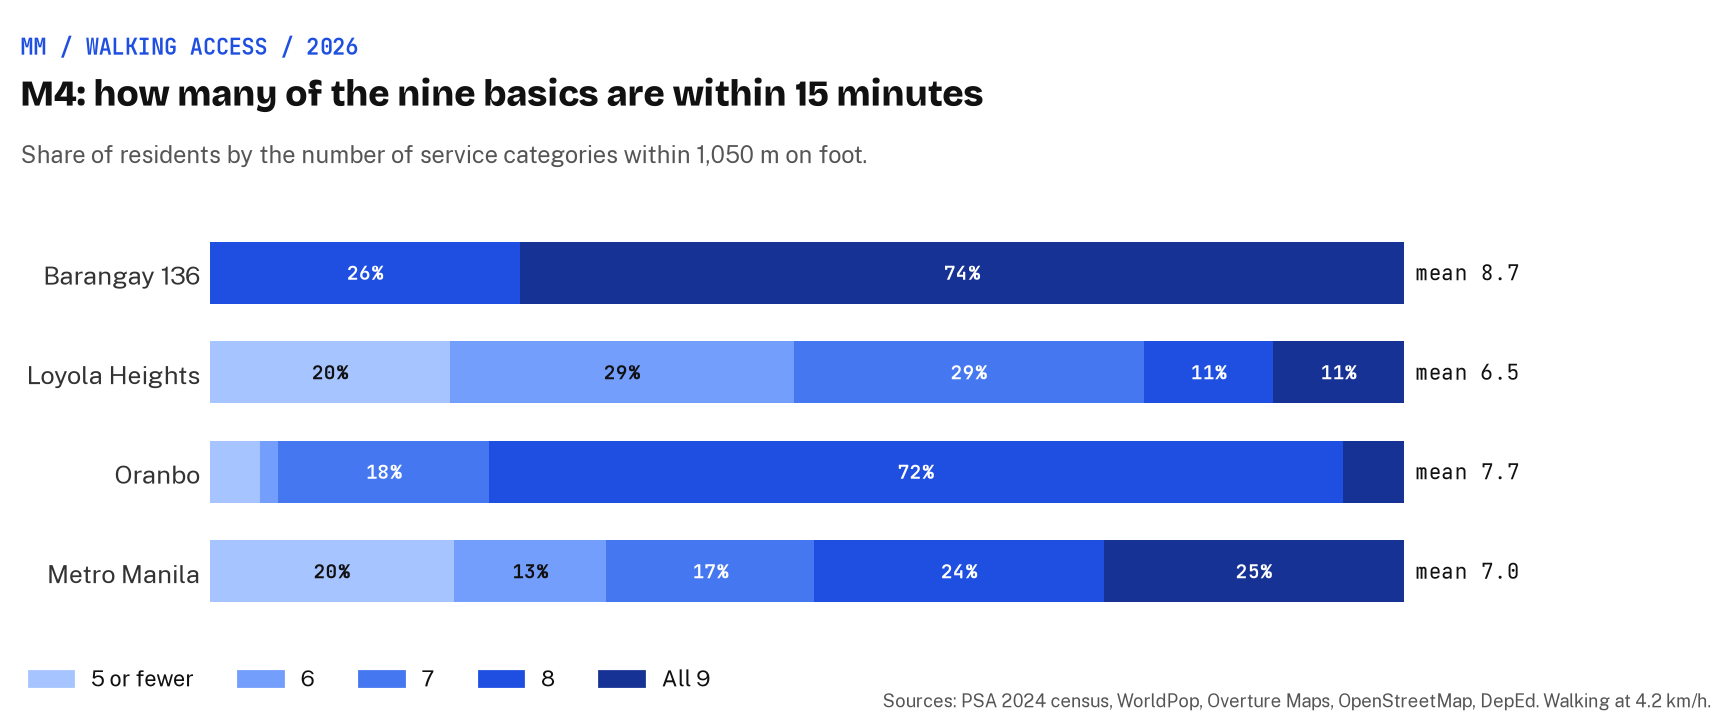

In [3]:
Image(charts.m4_chart(m))

**Reading.** On the headline measure, Barangay 136 has the most of the nine basics within 15 minutes (mean 8.7; 74% of residents have all nine), Oranbo next (7.7; 72% have eight), then Loyola Heights (6.5), below the Metro Manila mean of 7.0. In Barangay 136 the ninth category is usually open space, at the edge of 15 minutes; in Oranbo it is a public high school; in Loyola Heights the missing ones are mostly public schools and, for some, a hospital, a palengke or food.

In [4]:
m[(m.measure == "M5") & m.area.isin(AREAS)].pivot_table(index="stat", columns="area", values="value", sort=False)[
    AREAS
].round(3)

area,Barangay 136,Loyola Heights,Oranbo,Metro Manila
stat,,,,
share_within_500m_bus_jeepney,1.0,0.456,0.95,0.656
share_within_1km_rail,0.0,0.258,0.00,0.114
share_convenient,1.0,0.484,0.95,0.659


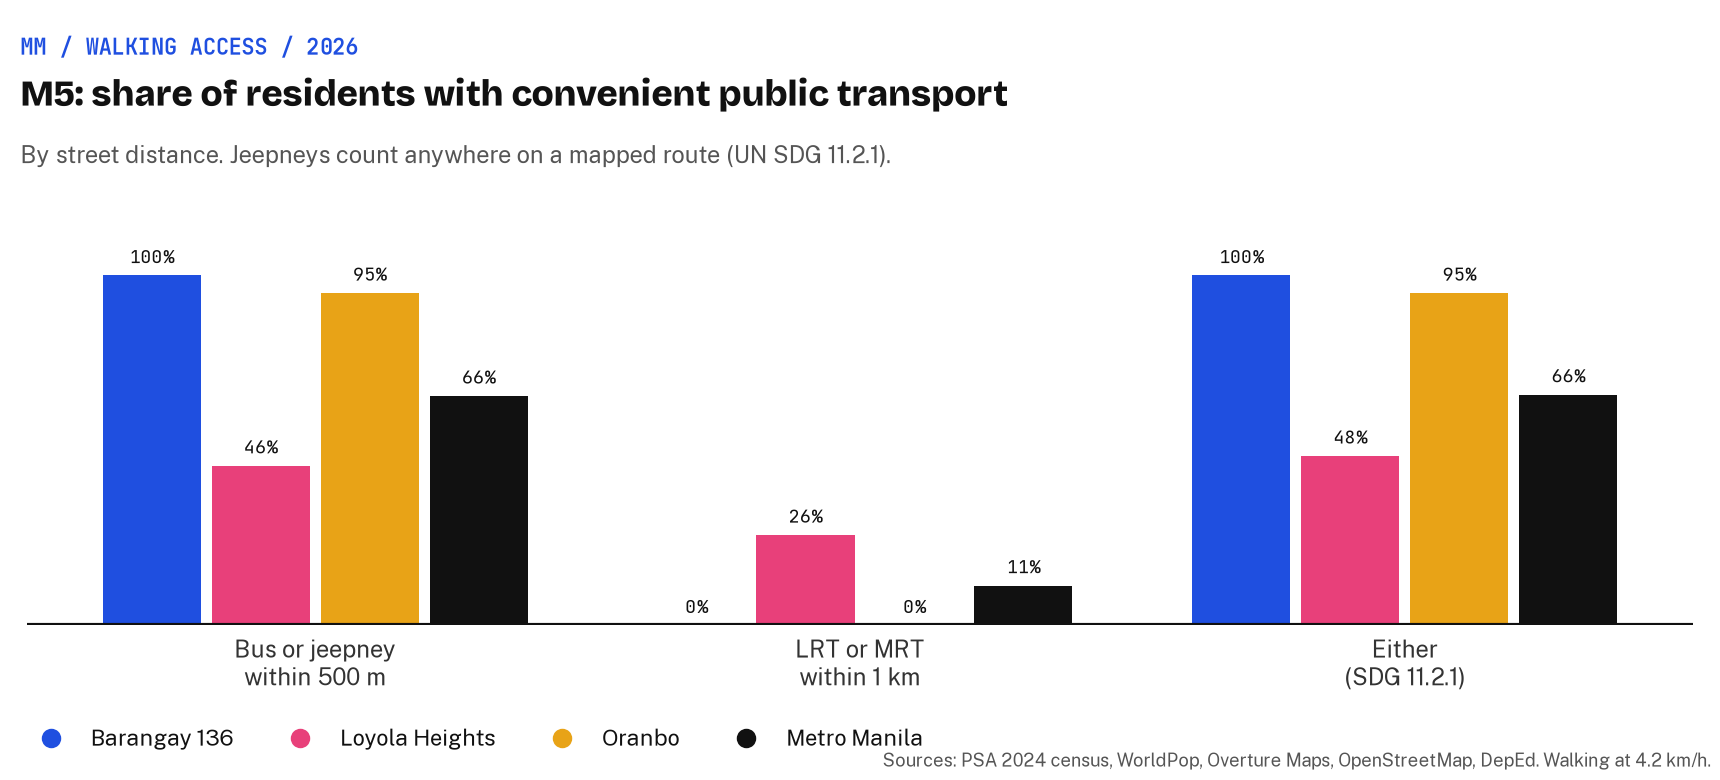

In [5]:
Image(charts.m5_chart(m))

**Reading.** By the SDG 11.2.1 test, every resident of Barangay 136 has convenient public transport, through bus and jeepney routes and stops within 500 m (none is within 1 km of an LRT or MRT station). Oranbo is close behind (95%, also without rail within 1 km). Loyola Heights is lowest at 48%: 46% are within 500 m of a mapped bus or jeepney stop or route and 26% within 1 km of an LRT-2 station. Metro Manila as a whole is at 66%. Jeepney routes are thinly mapped, so these shares are floors.